# 2 · More bits per symbol, and the price you pay

**NR link-level simulation from zero**, notebook 2 · [All notebooks](README.md) · [Glossary](GLOSSARY.md) · [![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/HelloSYQ/Claude/blob/HEAD/notebooks/learn/02_more_bits_per_symbol.ipynb)

**In one sentence:** more bits per symbol needs more arrows, more arrows sit closer together, and arrows that are closer together need a cleaner signal, so the best choice depends on the SNR.

**You will learn**
- the QAM constellations 5G uses, from QPSK (2 bits per symbol) to 1024QAM (10);
- how much more SNR each step costs;
- Shannon's limit: the most bits per symbol any system can deliver at a given SNR;
- why the base station changes the constellation as the signal quality changes.

**You need** notebooks 0 and 1. **Time:** about 20 minutes.

**How to use it.** Run the cells from top to bottom with Shift+Enter. The outputs are stored, so you can also just read.

In [1]:
# Setup: make the nrdlsim package importable, then import the basics.
# (On Google Colab this installs nrdlsim from GitHub the first time.)
import os, sys, subprocess, importlib.util
if importlib.util.find_spec("nrdlsim") is None:
    root = os.getcwd()
    while root != os.path.dirname(root) and not os.path.isdir(os.path.join(root, "nrdlsim")):
        root = os.path.dirname(root)
    if os.path.isdir(os.path.join(root, "nrdlsim")):
        sys.path.insert(0, root)              # running inside the repository
    else:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "git+https://github.com/HelloSYQ/Claude"], check=True)

import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams.update({"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})

def check(question, answer, expected, tol):
    """Say whether an answer is within tol of the expected value."""
    if answer is None:
        print(f"{question}: put your answer in place of None and run the cell again")
    elif abs(answer - expected) <= tol:
        print(f"{question}: yes, {answer} is right")
    else:
        print(f"{question}: not quite, try again (or open the answer below)")

## 1 · Bigger constellations

With 2^q arrows, each symbol carries q bits. 5G uses square constellations called **QAM** (quadrature amplitude modulation), in which both the length and the angle of the arrow carry information:

| constellation | arrows | bits per symbol |
|---|---|---|
| QPSK | 4 | 2 |
| 16QAM | 16 | 4 |
| 64QAM | 64 | 6 |
| 256QAM | 256 | 8 |
| 1024QAM | 1024 | 10 |

The transmit power doesn't grow with the constellation: the average symbol energy stays 1. So the more arrows there are, the closer together they sit.

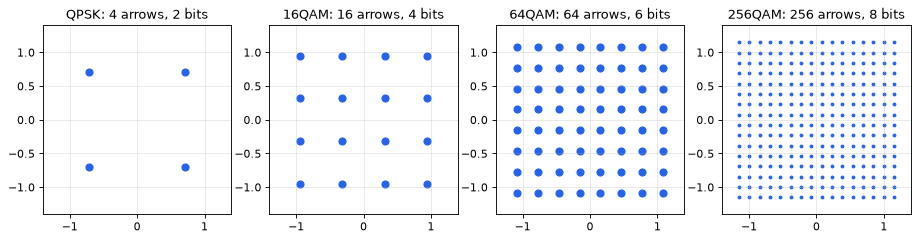

QPSK    average energy 1.00, closest two arrows 1.414 apart
16QAM   average energy 1.00, closest two arrows 0.632 apart
64QAM   average energy 1.00, closest two arrows 0.309 apart
256QAM  average energy 1.00, closest two arrows 0.153 apart


In [2]:
from nrdlsim.modulation import Modulator

names = {2: "QPSK", 4: "16QAM", 6: "64QAM", 8: "256QAM"}
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
for ax, (q, name) in zip(axes, names.items()):
    points = Modulator(q).constellation               # all 2^q arrows
    ax.scatter(points.real, points.imag, s=40 if q < 8 else 6, color="#2563eb")
    ax.set_xlim(-1.4, 1.4); ax.set_ylim(-1.4, 1.4); ax.set_aspect("equal")
    ax.set_title(f"{name}: {len(points)} arrows, {q} bits")
plt.show()

for q, name in names.items():
    points = Modulator(q).constellation
    gaps = np.abs(points[:, None] - points[None, :])   # distance between every pair of arrows
    print(f"{name:7s} average energy {np.mean(abs(points) ** 2):.2f}, "
          f"closest two arrows {gaps[gaps > 0].min():.3f} apart")

**What you see:** every constellation has an average energy of 1, but each step adds 2 bits and roughly halves the distance between neighbouring arrows. Halving a distance means a quarter of the power, about 6 dB. So to keep the same error rate, each step should need about 6 dB more SNR. Let's check.

## 2 · The same noise on different constellations

**Predict first:** at an SNR of 18 dB, which of 16QAM, 64QAM and 256QAM can still be read without many errors?

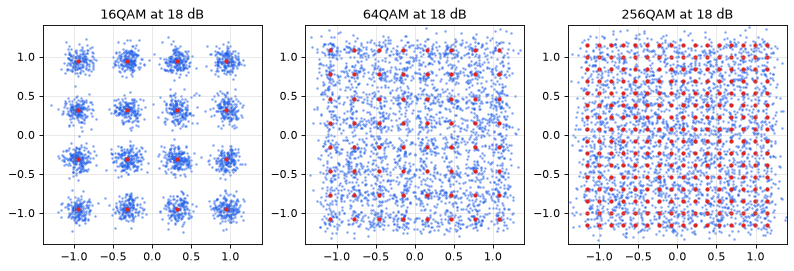

In [3]:
rng = np.random.default_rng(2)

def add_noise(symbols, snr_db, rng):                 # the same function as in notebook 1
    n0 = 10 ** (-snr_db / 10)
    return symbols + np.sqrt(n0 / 2) * (rng.standard_normal(symbols.size)
                                        + 1j * rng.standard_normal(symbols.size))

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, q in zip(axes, (4, 6, 8)):
    mod = Modulator(q)
    received = add_noise(mod.modulate(rng.integers(0, 2, q * 3000)), 18, rng)
    ax.scatter(received.real, received.imag, s=2, alpha=0.4, color="#2563eb")
    ax.scatter(mod.constellation.real, mod.constellation.imag, s=8, color="#dc2626")
    ax.set_xlim(-1.4, 1.4); ax.set_ylim(-1.4, 1.4); ax.set_aspect("equal")
    ax.set_title(f"{names[q]} at 18 dB")
plt.show()

**What you see:** at 18 dB the 16QAM clouds are well apart, the 64QAM clouds run into each other, and 256QAM is a blur in which many symbols would be misread.

## 3 · The price in SNR

Measure each constellation's bit error rate, deciding every bit by the sign of its LLR, the hard decision of notebook 1. (This cell takes 10 to 30 seconds, depending on the computer.)

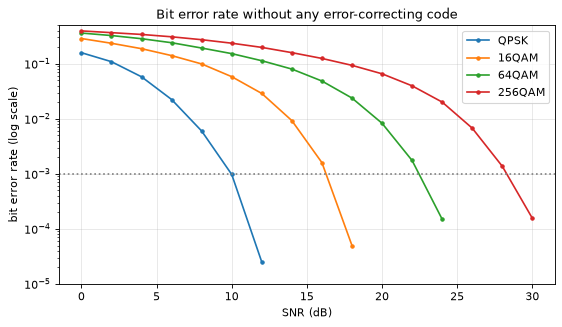

QPSK    needs about 10.0 dB for 1 bit error in 1000
16QAM   needs about 16.3 dB for 1 bit error in 1000
64QAM   needs about 22.5 dB for 1 bit error in 1000
256QAM  needs about 28.3 dB for 1 bit error in 1000


In [4]:
plt.figure(figsize=(8, 4.2))
needed = {}
for q, name in names.items():
    mod = Modulator(q)
    bits = rng.integers(0, 2, q * 20_000)
    sent = mod.modulate(bits)
    snrs = np.arange(0, 3 * q + 11, 2.0)              # far enough for the BER to drop below 1e-4
    ber = np.array([np.mean((mod.demodulate_llr(add_noise(sent, s, rng), 10 ** (-s / 10)) < 0)
                            != bits) for s in snrs])
    plt.semilogy(snrs, np.where(ber > 0, ber, np.nan), "o-", ms=3, label=name)
    # SNR at which the BER crosses 1/1000 (the BER falls with SNR, so interpolate on reversed arrays)
    needed[name] = np.interp(-3, np.log10(ber[::-1] + 1e-12), snrs[::-1])
plt.axhline(1e-3, ls=":", color="gray")
plt.ylim(1e-5, 0.5); plt.xlabel("SNR (dB)"); plt.ylabel("bit error rate (log scale)")
plt.title("Bit error rate without any error-correcting code"); plt.legend()
plt.show()
for name, s in needed.items():
    print(f"{name:7s} needs about {s:4.1f} dB for 1 bit error in 1000")

**What you see:** the curves have the same shape, shifted right by about 6 dB per step, just as the distances predicted. Each 2 extra bits per symbol cost about 6 dB, four times the SNR. Without coding, every constellation needs a lot of SNR to reach a usable error rate. Error-correcting codes (notebook 3) change that, and the next section shows how far they can go at best.

## 4 · How many bits can each constellation really carry?

Real systems never send uncoded bits: they add redundancy (notebook 3) and correct the errors. So the useful question is: **with the best possible code, how many useful bits per symbol can each constellation deliver at a given SNR?** Information theory answers it.

- In 1948 Claude Shannon proved that over a channel with Gaussian noise no scheme can carry more than
  $$C = \log_2(1 + \text{SNR}) \ \text{bits per symbol},$$
  with the SNR as a ratio. Below that rate, errors can be made as rare as you like; above it, they can't. This is the **Shannon capacity**.
- A given constellation does worse, and it can never carry more than its own bits per symbol. 5G combines QAM with a code in the way called *bit-interleaved coded modulation* (BICM), and the limit for each constellation is its **BICM capacity**. `nrdlsim.link_abstraction.bicm_capacity` provides it.

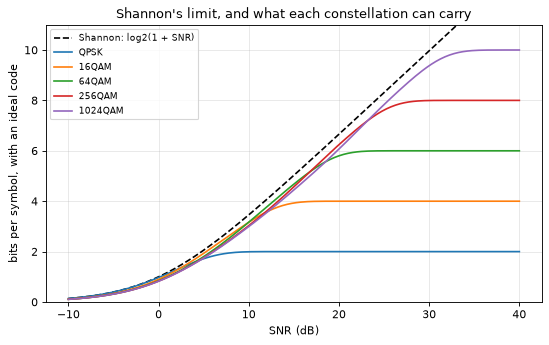

In [5]:
from nrdlsim.link_abstraction import bicm_capacity

snr_axis = np.linspace(-10, 40, 201)
shannon = np.log2(1 + 10 ** (snr_axis / 10))
all_names = {**names, 10: "1024QAM"}

plt.figure(figsize=(8, 4.5))
plt.plot(snr_axis, shannon, "k--", label="Shannon: log2(1 + SNR)")
for q, name in all_names.items():
    plt.plot(snr_axis, bicm_capacity(snr_axis, q), label=name)
plt.xlabel("SNR (dB)"); plt.ylabel("bits per symbol, with an ideal code"); plt.ylim(0, 11)
plt.title("Shannon's limit, and what each constellation can carry"); plt.legend(fontsize=8)
plt.show()

**What you see**

1. Each constellation follows Shannon's line at first, then bends and flattens at its own number of bits.
2. At low SNR the big constellations bring nothing: at 0 dB QPSK carries as much as any of them, in fact slightly more.
3. To keep up with Shannon's line at high SNR you need bigger constellations. So the base station should use a small constellation when the signal is weak and a big one when it is strong. Choosing it slot by slot is called **link adaptation** (notebook 4).

The table below picks, at each SNR, the smallest constellation that is (almost) as good as any of them:

In [6]:
print(" SNR   | Shannon | smallest constellation that is (almost) as good as any")
for s in (0, 5, 10, 15, 20, 25, 30):
    caps = {q: float(bicm_capacity(s, q)) for q in all_names}
    q_pick = min(q for q, c in caps.items() if c >= max(caps.values()) - 0.05)
    print(f"{s:3d} dB | {np.log2(1 + 10 ** (s / 10)):5.2f}   | "
          f"{all_names[q_pick]} ({caps[q_pick]:.2f} bits per symbol)")

 SNR   | Shannon | smallest constellation that is (almost) as good as any
  0 dB |  1.00   | QPSK (0.97 bits per symbol)
  5 dB |  2.06   | 16QAM (1.93 bits per symbol)
 10 dB |  3.46   | 16QAM (3.16 bits per symbol)
 15 dB |  5.03   | 64QAM (4.68 bits per symbol)
 20 dB |  6.66   | 256QAM (6.24 bits per symbol)
 25 dB |  8.31   | 1024QAM (7.84 bits per symbol)
 30 dB |  9.97   | 1024QAM (9.38 bits per symbol)


## 5 · From bits per symbol to bit/s/Hz

A channel of bandwidth B can carry about B symbols per second (notebook 6 shows how 5G does it, with many narrow subcarriers). So

$$\text{data rate} \approx B \times \text{bits per symbol}, \qquad \text{spectral efficiency} \approx \text{bits per symbol}.$$

That makes Shannon's limit a limit on notebook 0's spectral-efficiency curve. To compare like with like, simulate the simplest possible link: one antenna at each end and only noise on the way (AWGN), our running example otherwise. It takes a few seconds.

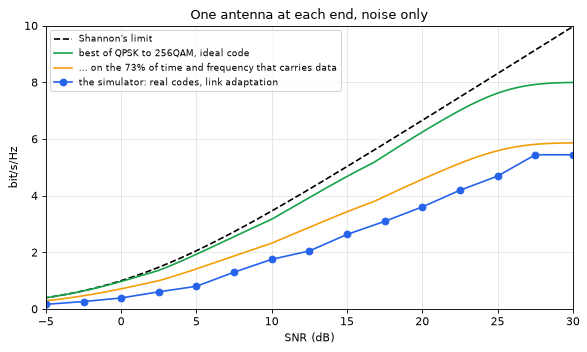

between 5 and 25 dB the simulator reaches 57% to 84% of the orange curve


In [7]:
from nrdlsim.config import SimConfig, CarrierConfig, PDSCHConfig, AntennaConfig, ChannelConfig
from nrdlsim.link_simulator import NRDownlinkSimulator
from nrdlsim import resource_grid

config = SimConfig(carrier=CarrierConfig(mu=1, n_size_grid=51),
                   pdsch=PDSCHConfig(num_rb=51, num_layers=1, mcs_table=2),
                   antenna=AntennaConfig(n_tx=1, n_rx=1),        # one antenna at each end
                   channel=ChannelConfig(model="AWGN"),          # nothing but noise
                   snr_db_range=(-5, 30, 2.5), num_slots=400)
results = NRDownlinkSimulator(config).run()
snr_sim = np.array([r.snr_db for r in results])
se_sim = np.array([r.spectral_efficiency for r in results])

best = np.max([bicm_capacity(snr_axis, q) for q in names], axis=0)   # best of QPSK...256QAM
# 12 subcarriers x 30 kHz x 0.5 ms = 180 symbols fit in one resource block per slot;
# this many of them carry data:
data_share = resource_grid.data_re_per_rb(config.pdsch) / (12 * 30e3 * 0.5e-3)

plt.figure(figsize=(8.5, 4.6))
plt.plot(snr_axis, shannon, "k--", label="Shannon's limit")
plt.plot(snr_axis, best, color="#16a34a", label="best of QPSK to 256QAM, ideal code")
plt.plot(snr_axis, best * data_share, color="#f59e0b",
         label=f"... on the {data_share:.0%} of time and frequency that carries data")
plt.plot(snr_sim, se_sim, "o-", color="#2563eb", label="the simulator: real codes, link adaptation")
plt.xlim(-5, 30); plt.ylim(0, 10)
plt.xlabel("SNR (dB)"); plt.ylabel("bit/s/Hz"); plt.legend(fontsize=8)
plt.title("One antenna at each end, noise only")
plt.show()

k = (snr_sim >= 5) & (snr_sim <= 25)
reached = se_sim[k] / (np.interp(snr_sim[k], snr_axis, best) * data_share)
print(f"between 5 and 25 dB the simulator reaches {reached.min():.0%} to "
      f"{reached.max():.0%} of the orange curve")

**What you see**, from top to bottom:

- **Shannon's line** (black) is the absolute limit.
- **The best constellation with an ideal code** (green) follows it a little below, and stops at 8 bits: the MCS table used here goes up to 256QAM.
- **Only part of the time and frequency carries data** (orange). Reference signals for measuring the channel, a control region, and a short guard interval in every symbol (the *cyclic prefix*, which absorbs echoes) take the rest (notebook 6).
- **The simulator** (blue dots) reaches only a little over half to about four fifths of the orange curve (printed above). Real LDPC codes need 1–2 dB more SNR than the limit (notebook 3); the system aims at about 10 % block errors and retransmits them; and it can only choose among 28 settings (notebook 4).

With several antennas, as in notebook 0, the curve can rise above Shannon's line. That is no contradiction: the SNR is measured at one antenna, and the antennas add gain and a second stream on top (notebook 7).

## 6 · Check yourself

**1.** How many bits does one 64QAM symbol carry?

In [8]:
answer = None
check("bits per 64QAM symbol", answer, expected=6, tol=0)

bits per 64QAM symbol: put your answer in place of None and run the cell again


<details><summary>Answer</summary>

6 bits, because 64 = 2⁶.

</details>

**2.** Using the capacity plot, at about what SNR can 16QAM carry 3 bits per symbol with an ideal code?

In [9]:
answer = None
check("SNR for 3 bits per symbol with 16QAM (dB)", answer,
      expected=float(np.interp(3.0, bicm_capacity(snr_axis, 4), snr_axis)), tol=1.0)

SNR for 3 bits per symbol with 16QAM (dB): put your answer in place of None and run the cell again


<details><summary>Answer</summary>

About 9 dB, 9.3 dB to be precise: `bicm_capacity(9.3, 4)` is about 3.

</details>

**3.** At 8 dB, why does 256QAM carry no more than 16QAM?

<details><summary>Answer</summary>

Its arrows are so close together that at 8 dB the noise blurs them. The code would have to add so much redundancy to repair the errors that the extra bits per symbol bring nothing.

</details>

## Where in the code

- `nrdlsim/modulation.py`: `Modulator` builds every constellation from the TS 38.211 rules (`Modulator.constellation`).
- `nrdlsim/link_abstraction.py`: `bicm_capacity`, used by the simulator to predict errors (notebook 8).
- `nrdlsim/mcs_tables.py`: which constellations and code rates 5G offers (notebook 4).

## Going further

- 3GPP TS 38.211, clauses 5.1.3 to 5.1.7: the QPSK, 16QAM, 64QAM, 256QAM and 1024QAM mappings.
- C. E. Shannon, "A mathematical theory of communication", 1948: where the limit comes from.
- G. Caire, G. Taricco and E. Biglieri, "Bit-interleaved coded modulation", IEEE Trans. Information Theory, 1998.

## Recap

- **QAM** constellations carry 2 to 10 bits per symbol; at the same power, more bits means arrows closer together.
- Each 2 extra bits per symbol cost about **6 dB** of SNR.
- **Shannon's limit**, log₂(1 + SNR), caps what any system can carry; each constellation tops out at its own number of bits.
- The best constellation depends on the SNR, which is why the base station adapts it (**link adaptation**).
- Real systems sit below the limit: overheads, practical codes and coarse settings each cost a little.

**Words you met:** QAM, bits per symbol, Shannon capacity, BICM, link adaptation, cyclic prefix. All are in the [glossary](GLOSSARY.md).

**Next:** notebook 3, error-correcting codes: how redundancy repairs errors. It comes in the next part of the series.